In [26]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import root_mean_squared_error
from sklearn.metrics import r2_score

In [27]:
df = pd.read_csv('dataset/advertising.csv')
df.head()

# Value : eg 37.8 = 378000 $

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


In [28]:
df[['TV','Sales']].describe()


,TV,Sales
count,200.000000,200.000000
mean,147.042500,15.130500
std,85.854236,5.283892
min,0.700000,1.600000
25%,74.375000,11.000000
50%,149.750000,16.000000
75%,218.825000,19.050000
max,296.400000,27.000000


Correltion : 0.9012079133023306


<Axes: ylabel='Density'>

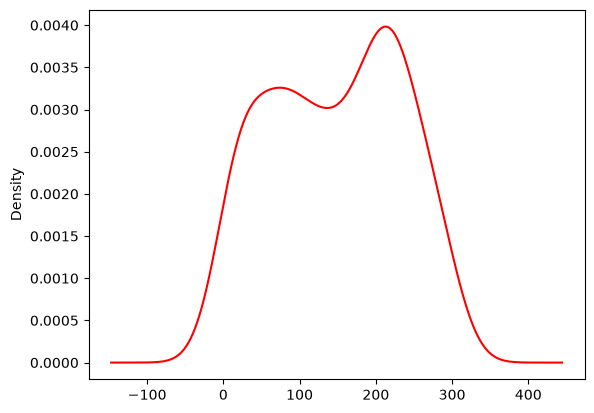

In [29]:
print("Correltion :", df['TV'].corr(df['Sales']))
df['TV'].plot(kind='kde',color='red')
# df['TV'].plot(kind='kde',color='red')

<Axes: xlabel='TV'>

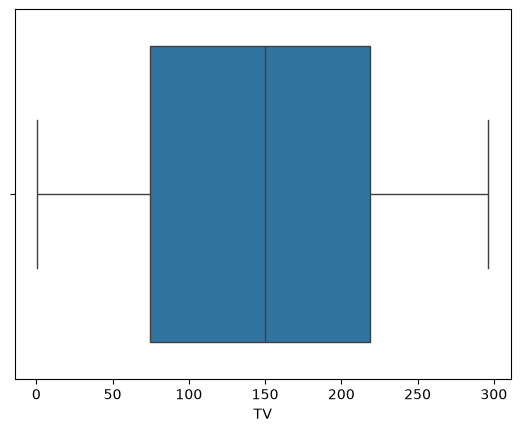

In [30]:
sns.boxplot(data=df, x='TV')

<Axes: ylabel='Density'>

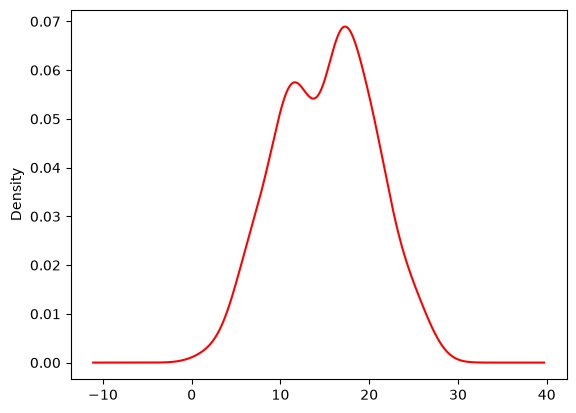

In [31]:
df['Sales'].plot(kind='kde',color='red')

In [32]:
print(df['TV'].skew())
print(df['TV'].kurt())

-0.06985336213274573
-1.2264948242299691


In [33]:
print(df['Sales'].skew())
print(df['Sales'].kurt())

-0.07373923537186912
-0.640074901678739


In [34]:
X = df[['TV']]
y = df['Sales']

Text(0, 0.5, 'Product sales')

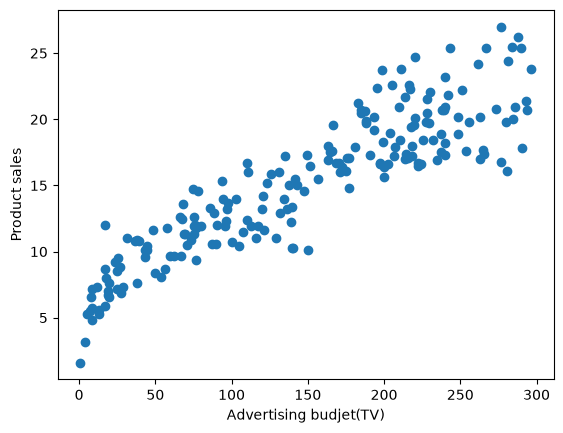

In [35]:
plt.scatter(X,y)
plt.xlabel('Advertising budjet(TV)')
plt.ylabel('Product sales')

In [36]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [37]:
model = LinearRegression()
model.fit(X_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[0.06]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['TV']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,7.007
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


In [38]:
print(model.coef_)
print(model.intercept_)

[0.05548294]
7.007108428241848


In [39]:
y_test.head()

95     16.9
15     22.4
30     21.4
158     7.3
128    24.7
Name: Sales, dtype: float64

In [40]:
y_pred = model.predict(X_test)

In [41]:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = root_mean_squared_error(y_test,y_pred)
r2 = r2_score(y_test,y_pred)

In [42]:
print("Mean absolute error : ", mae)
print("Mean squared error : ",mse)
print("Root Mean squared error : ",rmse)
print("R2 Score",r2)

Mean absolute error :  1.9502948931650088
Mean squared error :  6.101072906773963
Root Mean squared error :  2.470035001123256
R2 Score 0.802561303423698


In [43]:
comparison = pd.DataFrame({'Actual':y_test,'Predicted':y_pred})
comparison['error'] = y_test - y_pred 
comparison.head()

,Actual,Predicted,error
95,16.9,16.067473,0.832527
15,22.4,17.848476,4.551524
30,21.4,23.258063,-1.858063
158,7.3,7.656259,-0.356259
128,24.7,19.230001,5.469999


In [44]:
comparison['error'].describe()

count    40.000000
mean     -0.174796
std       2.495230
min      -6.481171
25%      -1.667958
50%      -0.489215
75%       1.310696
max       5.657334
Name: error, dtype: float64

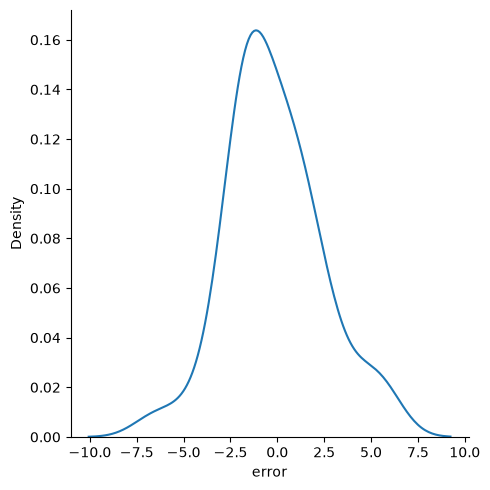

In [45]:
sns.displot(kind='kde',data=comparison,x='error')

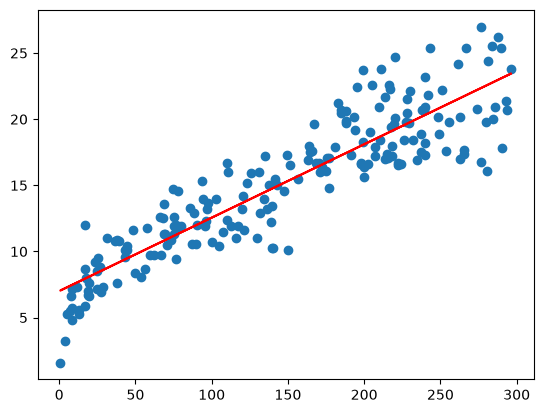

In [46]:
plt.scatter(X,y)
plt.plot(X,model.predict(X),color='red')

In [47]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(LinearRegression(),X_train,y_train,cv=5,scoring='r2')
print('scores' ,scores)
print('Mean R2' , scores.mean() , "\nStd : ",scores.std() )

scores [0.80161511 0.76850461 0.81402884 0.79381597 0.77342353]
Mean R2 0.7902776129020619 
Std :  0.017107328320632154


## Summary :
- The model predicts product sales from Advertising budget(TV) using a straight line.
- Its slope means the predicted sales increases by about 0.055 price units for each additional Advertising budget(TV) unit.
- The intercept is the model’s prediction at zero Advertising budget (TV) : 7.007. 
- The output is strongly rely on Advertising budget(TV).
